# 09 · Macroeconomic Stress Testing and the Business Case

| | |
|---|---|
| **Question** | How much would Meridian's live book lose in a recession, how much capital buffer does that require, and what is the whole risk platform worth? |
| **Inputs** | Live-book Expected Loss (notebook 08), FRED macro series, budget simulations (notebooks 06 and 07) |
| **Outputs** | `models/stress_satellite.joblib`, scenario losses, capital buffer, consolidated ROI |
| **Skills shown** | Hazard-rate SQL, confounding diagnosis, satellite (macro-to-credit) regression on changes, Fed-style scenarios, sensitivity analysis |

### Approach in three steps

1. **Can Meridian's own data measure macro sensitivity?** Test it, and explain why not.
2. **Satellite model on an industry proxy** with complete credit cycles: US credit card charge-off rates since 1985.
3. **Apply scenarios** (baseline, adverse, severely adverse) to every loan in the live book.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from meridian import config, viz
from meridian.db import connect, load_sql, run_sql
from meridian.stress import SCENARIOS, SatelliteModel, stressed_expected_loss

viz.set_style()
con = connect()
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"
RECESSIONS = [("1990-07-01", "1991-03-01"), ("2001-03-01", "2001-11-01"), ("2007-12-01", "2009-06-01")]
macro = con.execute("select * from gold.mart_macro_monthly where month < date '2020-01-01'").df()

## 1. Can Lending Club's own history measure macro sensitivity?

The query below computes the quarterly default rate of the **active** book (a hazard rate): loans that defaulted in the quarter divided by loans still outstanding at that time.

In [2]:
print(load_sql("q09_default_hazard_by_quarter"))
hz = run_sql(con, "q09_default_hazard_by_quarter")
hz = hz.merge(macro.assign(quarter=macro.month.dt.to_period("Q").dt.start_time)
                   .groupby("quarter").unemployment_rate.mean().reset_index(), on="quarter")

-- Q9. Quarterly default rate of the active book (a hazard rate).
-- Each loan is "active" from its issue quarter until it defaults, is paid off,
-- or reaches the snapshot. Uses an event-count pattern with running window
-- sums instead of exploding loans x quarters (2.26M x 48 rows).
with spans as (
    select
        cast(date_trunc('quarter', issue_month) as date)                       as start_q,
        cast(date_trunc('quarter', case
            when is_defaulted                then est_default_month
            when loan_status = 'Fully Paid'  then coalesce(last_payment_month, issue_month)
            else date '2019-03-01' end) as date)                                as end_q,
        is_defaulted
    from silver.int_loans__outcomes
    where not is_policy_exception
),
starts as (select start_q as q, count(*) as n_start from spans group by 1),
ends   as (select end_q as q, count(*) as n_end, count(*) filter (where is_defaulted) as n_default
           from spans group by 1),
g

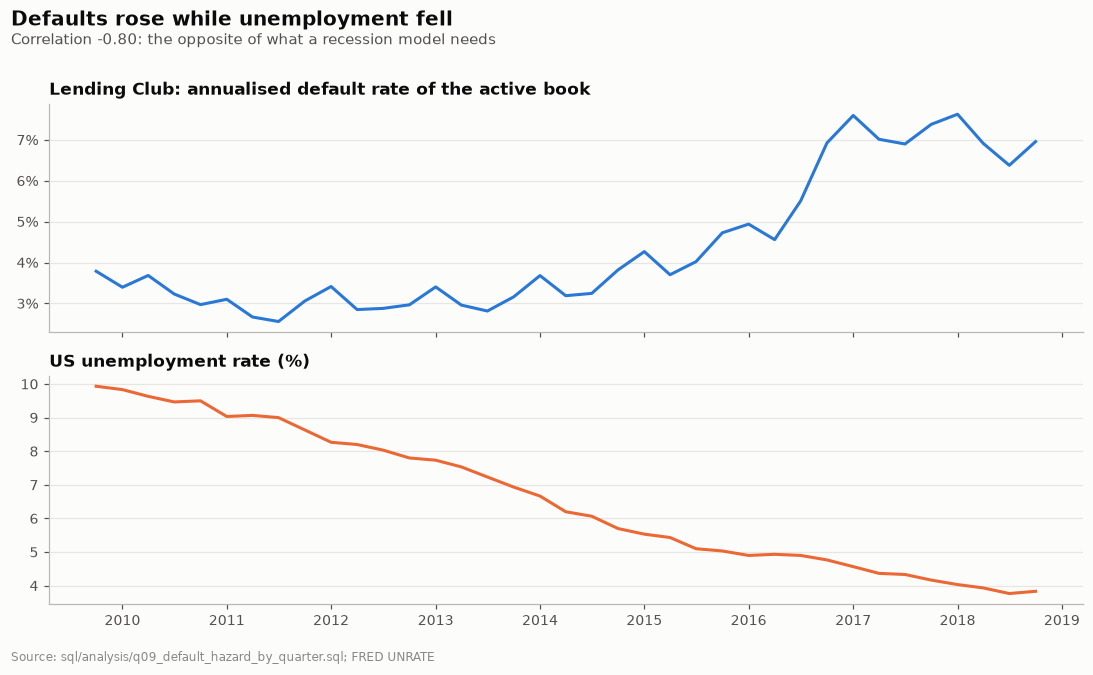

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
axes[0].plot(hz.quarter, hz.annualised_default_rate, color=viz.BLUE)
viz.pct(axes[0])
axes[0].set_title("Lending Club: annualised default rate of the active book", fontsize=11, pad=6)
axes[1].plot(hz.quarter, hz.unemployment_rate, color=viz.ORANGE)
axes[1].set_title("US unemployment rate (%)", fontsize=11, pad=6)
corr = hz[["annualised_default_rate", "unemployment_rate"]].corr().iloc[0, 1]
fig.suptitle("Defaults rose while unemployment fell", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.text(0.01, 0.975, f"Correlation {corr:+.2f}: the opposite of what a recession model needs", fontsize=9.5, color=viz.INK_2)
fig.tight_layout()
viz.source(fig, "sql/analysis/q09_default_hazard_by_quarter.sql; FRED UNRATE", y=-0.01)
plt.show()

**Why Lending Club's own data cannot be used:**

- Between 2010 and 2018 unemployment fell from 10% to under 4%, yet the default rate of the active book **rose**. A regression on this data would conclude that recessions *reduce* defaults.
- Two things move together and cannot be separated: the book was **seasoning** (most loans were new in 2013 to 2015 and reached their peak default age, 12 to 24 months, a little later), and **underwriting loosened** (notebook 01). Both pushed defaults up while the economy improved.
- The book was tiny during the 2008 to 2009 recession (under USD 100M), so there is no downturn to learn from.

This is the classic situation for a young lender. Supervisors accept a **satellite model** estimated on a longer industry series with similar products, transferred to the lender's own PDs.

## 2. The industry proxy: 35 years of credit card charge-offs

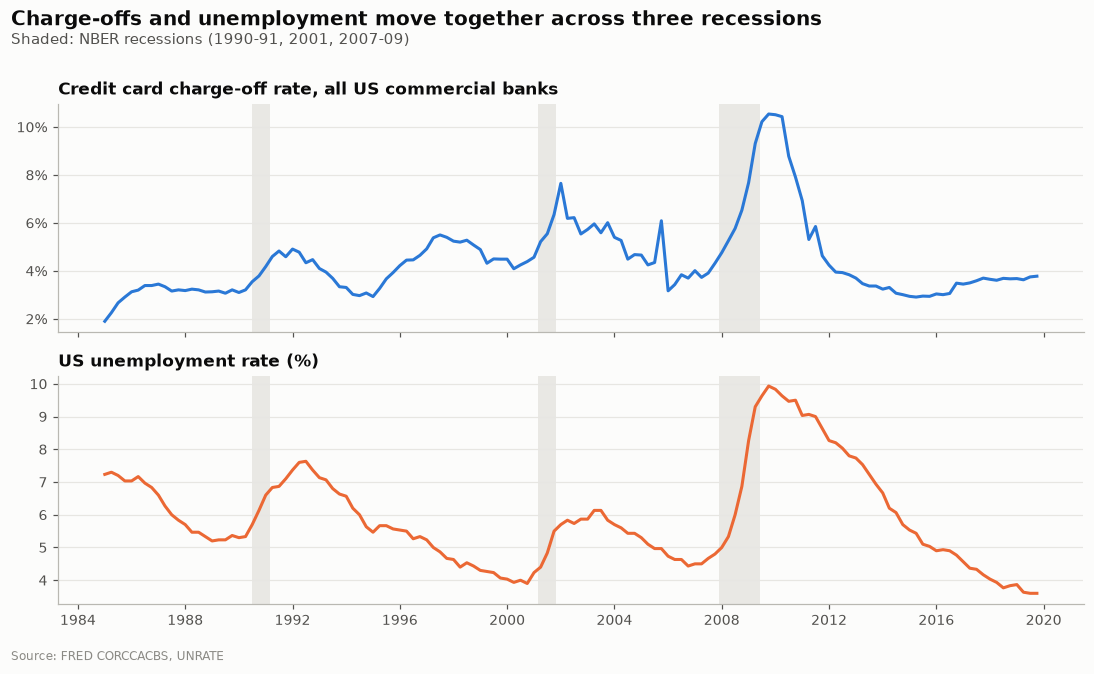

In [4]:
q = macro.set_index("month")[["card_chargeoff_rate", "unemployment_rate"]].resample("QS").mean().dropna()
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
axes[0].plot(q.index, q.card_chargeoff_rate / 100, color=viz.BLUE)
viz.pct(axes[0])
axes[0].set_title("Credit card charge-off rate, all US commercial banks", fontsize=11, pad=6)
axes[1].plot(q.index, q.unemployment_rate, color=viz.ORANGE)
axes[1].set_title("US unemployment rate (%)", fontsize=11, pad=6)
for ax in axes:
    for a, b in RECESSIONS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=viz.GRID, alpha=0.9, lw=0)
fig.suptitle("Charge-offs and unemployment move together across three recessions", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.03)
fig.text(0.01, 0.975, "Shaded: NBER recessions (1990-91, 2001, 2007-09)", fontsize=9.5, color=viz.INK_2)
fig.tight_layout()
viz.source(fig, "FRED CORCCACBS, UNRATE", y=-0.01)
plt.show()

Unsecured credit card lending is the closest product to Meridian's unsecured personal loans, and the series covers three recessions. In 2009 card charge-offs reached 10.5%, about 2.6 times their pre-crisis level.

## 3. The satellite model

Charge-off **levels** drift over decades for reasons unrelated to the economy (product mix, regulation such as the 2009 CARD Act). Regressing levels on unemployment would mix that drift with the cycle. The model therefore uses **year-over-year changes**:

$$\ln CO_t - \ln CO_{t-4} = a + b \,(U_t - U_{t-4}) + \varepsilon_t$$

The slope *b* is an elasticity: by how many percent charge-offs rise for each 1-point rise in unemployment.

In [5]:
sat = SatelliteModel.fit(macro, baseline_unemployment=3.9)
dfq = pd.DataFrame({"dy": np.log(q.card_chargeoff_rate).diff(4), "du": q.unemployment_rate.diff(4)}).dropna()
ols = sm.OLS(dfq.dy, sm.add_constant(dfq.du)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(ols.summary().tables[1])
print(f"\nR-squared {sat.r_squared:.2f} on {sat.n_quarters} quarters. A 1-point rise in unemployment raises "
      f"charge-offs by {np.exp(sat.slope) - 1:.1%}.")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0301      0.026      1.177      0.239      -0.020       0.080
du             0.1674      0.018      9.377      0.000       0.132       0.202

R-squared 0.44 on 136 quarters. A 1-point rise in unemployment raises charge-offs by 18.2%.


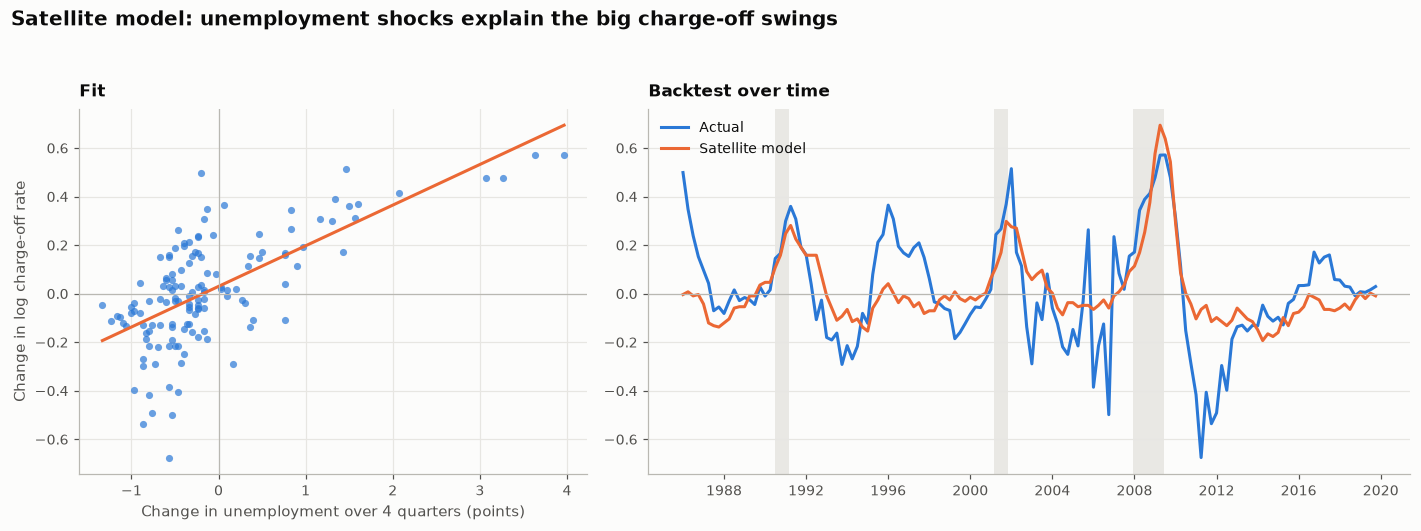

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.scatter(dfq.du, dfq.dy, s=22, color=viz.BLUE, alpha=0.7)
xs = np.linspace(dfq.du.min(), dfq.du.max(), 50)
ax.plot(xs, sat.intercept + sat.slope * xs, color=viz.ORANGE, lw=2)
ax.axhline(0, color=viz.NEUTRAL, lw=0.8)
ax.axvline(0, color=viz.NEUTRAL, lw=0.8)
ax.set_xlabel("Change in unemployment over 4 quarters (points)")
ax.set_ylabel("Change in log charge-off rate")
ax.grid(axis="x", color=viz.GRID)
ax.set_title("Fit", fontsize=11, pad=8)

ax = axes[1]
fitted = sat.intercept + sat.slope * dfq.du
ax.plot(dfq.index, dfq.dy, color=viz.BLUE, label="Actual")
ax.plot(dfq.index, fitted, color=viz.ORANGE, label="Satellite model")
ax.axhline(0, color=viz.NEUTRAL, lw=0.8)
for a, b in RECESSIONS:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=viz.GRID, alpha=0.9, lw=0)
ax.legend(loc="upper left")
ax.set_title("Backtest over time", fontsize=11, pad=8)
fig.suptitle("Satellite model: unemployment shocks explain the big charge-off swings", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()

**What it means:** the model captures every recession spike (1991, 2001, 2009) and the post-2010 normalisation, with an R-squared of about 0.44 on year-over-year changes, which is a strong fit for changes rather than levels. Standard errors use a HAC correction because overlapping 4-quarter changes are autocorrelated.

**Sanity check:** from 2007 to 2009 unemployment rose about 5.3 points. The model implies a charge-off multiplier of exp(0.167 x 5.3), about 2.4 times; the actual rise was about 2.6 times.

## 4. Scenarios

The scenarios follow the structure of the US Federal Reserve's annual stress tests: a baseline, a moderate recession and a severe recession over a two-year horizon, starting from the March 2019 unemployment rate of 3.9%.

In [7]:
scen = pd.DataFrame([{"scenario": s.name, "peak_unemployment": s.unemployment_rate, "lgd_used": "Downturn" if s.use_downturn_lgd else "Long-run",
                      "pd_multiplier": float(sat.multiplier(s.unemployment_rate)), "description": s.description} for s in SCENARIOS])
scen.style.format({"peak_unemployment": "{:.1f}%", "pd_multiplier": "{:.2f}x"}).hide(axis="index")

scenario,peak_unemployment,lgd_used,pd_multiplier,description
Baseline,3.9%,Long-run,1.00x,Unemployment stays at its March 2019 level
Adverse,7.0%,Downturn,1.68x,"Moderate recession, unemployment rises about 3 points"
Severely adverse,10.0%,Downturn,2.78x,"2008-09 style recession, unemployment peaks at 10%"


## 5. Stressed Expected Loss on the live book

In [8]:
book = pd.read_parquet(config.DATA_DIR / "app" / "live_book_el.parquet")

# Only defaults expected inside the 2-year scenario horizon are stressed.
curves = con.execute("""
    select term_months, months_on_book, sum(cumulative_defaults) / sum(loans) as cdr
    from gold.mart_vintage_curves
    where (term_months = 36 and vintage_year between 2013 and 2015)
       or (term_months = 60 and vintage_year between 2012 and 2013)
    group by all order by all""").df()
curves["share"] = curves.cdr / curves.groupby("term_months").cdr.transform("max")
def share_at(term, mob):
    c = curves[curves.term_months == term]
    return np.interp(mob, c.months_on_book, c.share)
HORIZON = 24
now = np.array([share_at(t, m) for t, m in zip(book.term_months, book.months_on_book)])
later = np.array([share_at(t, m + HORIZON) for t, m in zip(book.term_months, book.months_on_book)])
with np.errstate(divide="ignore", invalid="ignore"):
    book["share_in_horizon"] = np.where(now < 1, (later - now) / np.maximum(1 - now, 1e-9), 1.0)
book.loc[book.loan_status.str.startswith("Late"), "share_in_horizon"] = 1.0
print(f"Share of remaining default risk inside the 24-month horizon (exposure-weighted): "
      f"{np.average(book.share_in_horizon, weights=book.outstanding_principal):.0%}")

for s in SCENARIOS:
    book[f"el_{s.name}"] = stressed_expected_loss(book, sat, s)
cols = [f"el_{s.name}" for s in SCENARIOS]
outstanding = book.outstanding_principal.sum()
totals = pd.DataFrame({"expected_loss": book[cols].sum().values,
                       "el_rate": book[cols].sum().values / outstanding},
                      index=[s.name for s in SCENARIOS])
totals["increase_vs_baseline"] = totals.expected_loss - totals.expected_loss.iloc[0]
print(f"Live book: {len(book):,} loans, outstanding ${outstanding / 1e9:.2f}B")
totals.style.format({"expected_loss": "${:,.0f}", "el_rate": "{:.2%}", "increase_vs_baseline": "${:,.0f}"})

Share of remaining default risk inside the 24-month horizon (exposure-weighted): 83%
Live book: 900,033 loans, outstanding $9.48B


,expected_loss,el_rate,increase_vs_baseline
Baseline,"$1,296,640,050",13.68%,$0
Adverse,"$2,031,547,726",21.43%,"$734,907,677"
Severely adverse,"$2,973,715,528",31.37%,"$1,677,075,479"


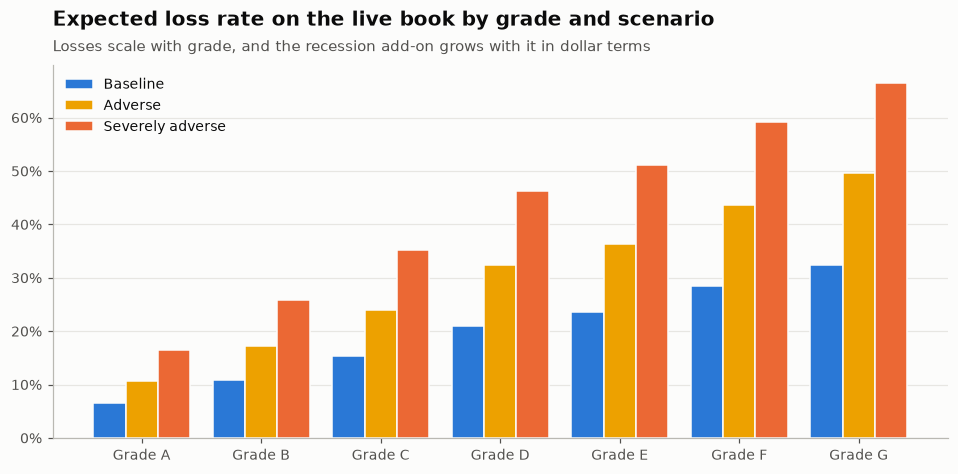

In [9]:
by_grade = book.groupby("grade")[["outstanding_principal"] + cols].sum()
rates = by_grade[cols].div(by_grade.outstanding_principal, axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.4))
x = np.arange(len(rates))
for i, (c, color, name) in enumerate(zip(cols, [viz.BLUE, viz.YELLOW, viz.ORANGE], [s.name for s in SCENARIOS])):
    ax.bar(x + (i - 1) * 0.27, rates[c], 0.27, color=color, label=name, edgecolor=viz.SURFACE, linewidth=1)
ax.set_xticks(x, [f"Grade {g}" for g in rates.index])
viz.pct(ax)
ax.legend(loc="upper left")
ax.set_title("Expected loss rate on the live book by grade and scenario")
viz.subtitle(ax, "Losses scale with grade, and the recession add-on grows with it in dollar terms")
plt.show()

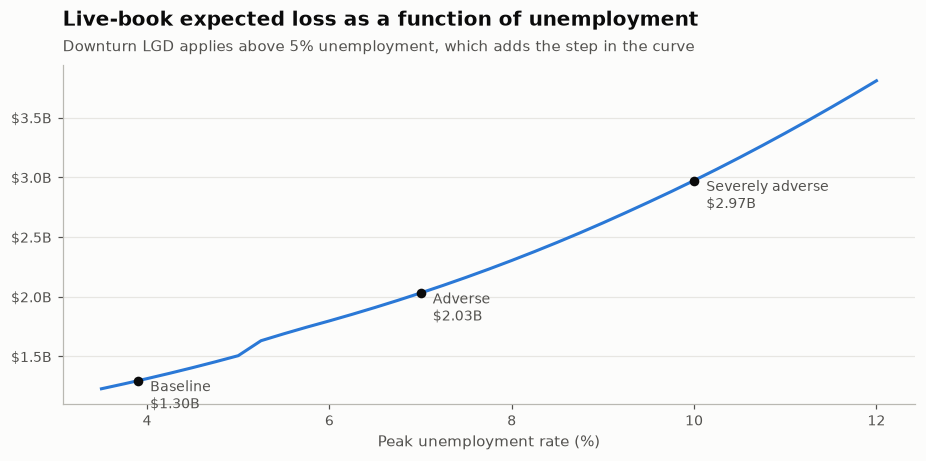

In [10]:
grid = np.linspace(3.5, 12, 35)
curve = [stressed_expected_loss(book, sat, type(SCENARIOS[0])("x", u, u > 5.0, "")).sum() for u in grid]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid, curve, color=viz.BLUE)
for s in SCENARIOS:
    v = stressed_expected_loss(book, sat, s).sum()
    ax.scatter([s.unemployment_rate], [v], color=viz.INK, s=40, zorder=3)
    ax.annotate(f"{s.name}\n${v / 1e9:.2f}B", (s.unemployment_rate, v), xytext=(8, -18), textcoords="offset points",
                fontsize=9, color=viz.INK_2)
viz.money(ax)
ax.set_xlabel("Peak unemployment rate (%)")
ax.set_title("Live-book expected loss as a function of unemployment")
viz.subtitle(ax, "Downturn LGD applies above 5% unemployment, which adds the step in the curve")
plt.show()

## 6. Capital buffer

The stress is applied only to defaults expected within the two-year scenario horizon (most of the remaining risk for young loans, less for older ones); defaults expected after the recession keep their baseline probability. Expected loss under the baseline is covered by provisions and pricing. The **additional** loss in a severe recession is what capital must absorb. The difference between the severely adverse and baseline scenarios is the stress capital buffer Meridian should hold against this book.

In [11]:
buffer = totals.loc["Severely adverse", "expected_loss"] - totals.loc["Baseline", "expected_loss"]
print(f"Stress capital buffer (severe minus baseline): ${buffer / 1e6:,.0f}M  = {buffer / outstanding:.2%} of outstanding principal")
joblib.dump(sat, MODELS_DIR / "stress_satellite.joblib")
totals.to_csv(REPORTS / "stress_test_results.csv")

Stress capital buffer (severe minus baseline): $1,677M  = 17.69% of outstanding principal


**Is a 30% loss rate in a severe recession plausible?** Lending Club's own 2007 vintage, the only one that lived through the 2008 to 2009 recession, ended with 26% of its loans defaulting (notebook 01, Q3), from a borrower base screened more strictly than in 2016 to 2018. A severe-scenario loss rate around 30% of outstanding balance for today's riskier, younger book is in line with that history.

## 7. The business case for the whole platform

The figures below are read from the reports written by earlier notebooks, so this summary updates automatically if any model changes.

In [12]:
budget = pd.read_csv(REPORTS / "pd_budget_simulation.csv")
b50 = budget[budget.budget == 0.5].set_index("strategy")
comparison = pd.read_csv(REPORTS / "pd_model_comparison.csv").set_index("dataset")
case = pd.DataFrame({
    "Value": [
        f"{comparison.loc['Meridian challenger (LightGBM, 47 variables)', 'gini']:.3f} vs {comparison.loc['Lending Club sub-grade (benchmark)', 'gini']:.3f}",
        f"${(b50.loc['Expected profit, Meridian challenger', 'profit'] - b50.loc['Random selection (no model)', 'profit']) / 1e6:,.0f}M",
        f"${(b50.loc['Expected profit, Meridian challenger', 'profit'] - b50.loc['Expected profit, Lending Club grade PD', 'profit']) / 1e6:,.0f}M",
        f"{b50.loc['Expected profit, Meridian challenger', 'default_rate']:.1%} vs {b50.loc['Expected profit, Lending Club grade PD', 'default_rate']:.1%}",
        f"${totals.loc['Baseline', 'expected_loss'] / 1e6:,.0f}M ({totals.loc['Baseline', 'el_rate']:.1%})",
        f"${buffer / 1e6:,.0f}M ({buffer / outstanding:.1%} of book)",
    ]},
    index=["Out-of-time Gini: Meridian challenger vs Lending Club grade",
           "Extra profit vs no model, 50% capital budget, 2016 loans",
           "Extra profit vs Lending Club grade, same budget",
           "Default rate of funded book: Meridian vs Lending Club grade",
           "Live-book loss provision (baseline Expected Loss)",
           "Stress capital buffer for a 2008-style recession"])
case

,Value
Out-of-time Gini: Meridian challenger vs Lending Club grade,0.401 vs 0.378
"Extra profit vs no model, 50% capital budget, 2016 loans",$195M
"Extra profit vs Lending Club grade, same budget",$15M
Default rate of funded book: Meridian vs Lending Club grade,16.8% vs 20.9%
Live-book loss provision (baseline Expected Loss),"$1,297M (13.7%)"
Stress capital buffer for a 2008-style recession,"$1,677M (17.7% of book)"


## 8. Conclusions and limitations

1. **Meridian's own history cannot measure recession risk.** Its defaults rose as the economy improved, because of seasoning and looser underwriting. Using it naively would understate recession losses.
2. **The satellite model** transfers 35 years of industry experience: each extra point of unemployment raises charge-offs by about 18%. A 2008-style recession multiplies default rates by about 2.8.
3. **The stress capital buffer** quantifies how much capital this book needs beyond provisions to survive a severe recession, the number a CFO and a regulator ask for first.

**Limitations:** the transfer assumes Meridian's borrowers react to unemployment like the average US card holder. Personal-loan borrowers are often more leveraged, so the elasticity could be higher. A production model would add the credit spread and house prices, and would project losses quarter by quarter over the scenario horizon rather than applying a single peak multiplier.

**Next:** notebook 10 moves to the payments business and builds the fraud model.